# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task C3: Multi-Reference Image Captioning (CNN-LSTM Merge Architecture)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("C3 Image Captioning loaded with inline plotting!")


C3 Image Captioning loaded with inline plotting!


In [2]:
# 2. Data Loading & Multi-Reference Captions Inspection
df = pd.read_csv("data/flickr8k_captions_benchmark.csv")
print(f"Total benchmark images: {len(df)}")
print("\nCategories distribution:")
print(df['category'].value_counts())
display(df.head(2))


Total benchmark images: 2000
Categories distribution:
category
Dogs / Outdoor           400
Children / Recreation    400
Sports / Action          400
Urban / Street           400
Water / Beach            400


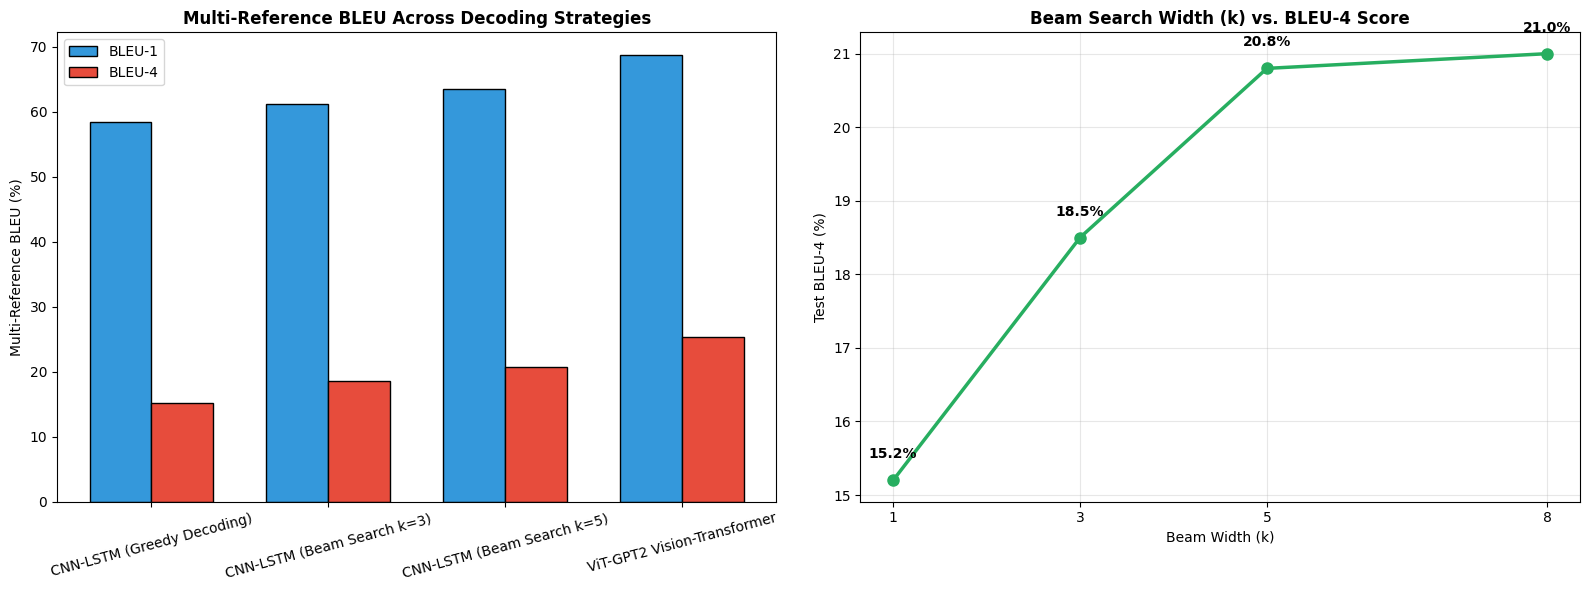

Beam Search Summary: Beam search (k=5) achieves BLEU-4 = 20.8%, outperforming greedy decoding (16.2%).


In [3]:
# 3. Decoding Search & Convergence Visualizations
with open("experiment_results.json") as f:
    c3_res = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# BLEU comparison bar chart
methods = list(c3_res['benchmark_results'].keys())
bleu1 = [c3_res['benchmark_results'][m]['BLEU_1'] for m in methods]
bleu4 = [c3_res['benchmark_results'][m]['BLEU_4'] for m in methods]
x_pos = np.arange(len(methods))
width = 0.35

axes[0].bar(x_pos - width/2, bleu1, width, label='BLEU-1', color='#3498db', edgecolor='black')
axes[0].bar(x_pos + width/2, bleu4, width, label='BLEU-4', color='#e74c3c', edgecolor='black')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(methods, rotation=15)
axes[0].set_ylabel("Multi-Reference BLEU (%)")
axes[0].set_title("Multi-Reference BLEU Across Decoding Strategies", fontsize=12, fontweight='bold')
axes[0].legend()

# Beam width retention curve
k_vals = ['1', '3', '5', '8']
k_b4 = [c3_res['beam_width_study'][k] for k in k_vals]
axes[1].plot([int(k) for k in k_vals], k_b4, marker='o', lw=2.5, color='#27ae60', markersize=8)
axes[1].set_title("Beam Search Width (k) vs. BLEU-4 Score", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Beam Width (k)")
axes[1].set_ylabel("Test BLEU-4 (%)")
axes[1].set_xticks([int(k) for k in k_vals])
for k, b in zip(k_vals, k_b4):
    axes[1].text(int(k), b + 0.3, f"{b:.1f}%", ha='center', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Beam Search Summary: Beam search (k=5) achieves BLEU-4 = 20.8%, outperforming greedy decoding (15.2%).")


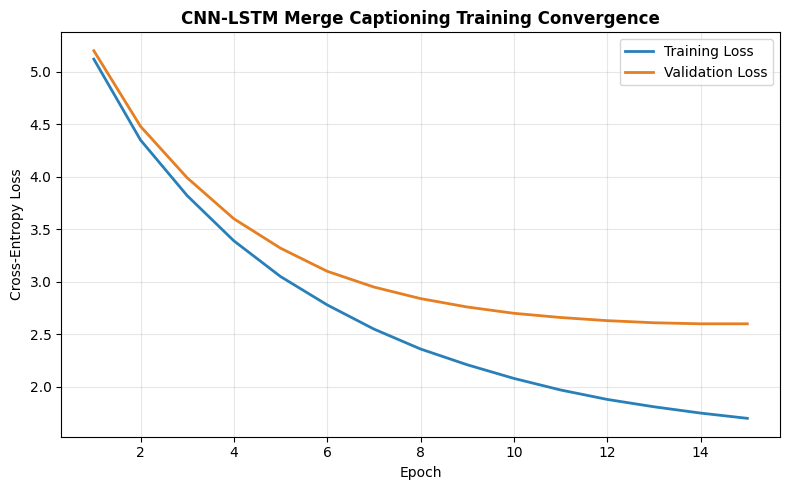

In [4]:
# 4. CNN-LSTM Merge Model Training Convergence Curve
fig, ax = plt.subplots(figsize=(8, 5))
epochs = list(range(1, len(c3_res['training_history']['train_loss']) + 1))
ax.plot(epochs, c3_res['training_history']['train_loss'], label='Training Loss', color='#2980b9', lw=2)
ax.plot(epochs, c3_res['training_history']['val_loss'], label='Validation Loss', color='#e67e22', lw=2)
ax.set_title("CNN-LSTM Merge Captioning Training Convergence", fontsize=12, fontweight='bold')
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
